# Lựa chọn đặc trưng: ba phương pháp

Notebook triển khai Correlation Heatmap, Mutual Information và Permutation Importance cho bài toán dự báo độ biến động. Phân tích chỉ sử dụng train và các fold validation theo thời gian; tập test không tham gia lựa chọn feature. Kết quả là căn cứ sàng lọc, không tự động loại bỏ đặc trưng.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.feature_selection import mutual_info_regression
from sklearn.inspection import permutation_importance
from sklearn.metrics import average_precision_score
from xgboost import XGBRegressor

ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.config import load_config
from src.pipeline.dataset import prepare_dataset, feature_matrix
from src.risk.warning_engine import WarningEngine

config = load_config(ROOT / "config.yaml")
ticker = config["data"].get("ticker", "ACB")
dataset = prepare_dataset(ticker, config)
features, target = dataset.features, dataset.target
train = dataset.train
X_train = feature_matrix(train, features)
y_train = train[target].to_numpy(dtype=float)
warning = WarningEngine(**config["warning"]).fit(y_train)

print(f"Mã cổ phiếu: {ticker} | mục tiêu: {target} | số mẫu train: {len(train):,}")
print(f"Số đặc trưng: {len(features)} | số fold validation: {len(dataset.validation_folds)}")
print("Đặc trưng:", ", ".join(features))

Mã cổ phiếu: ACB | mục tiêu: target_volatility_5d | số mẫu train: 1,639
Số đặc trưng: 14 | số fold validation: 5
Đặc trưng: return_1d, return_5d, return_10d, return_20d, close_to_ma_5, close_to_ma_10, close_to_ma_20, close_to_ma_50, rolling_volatility_5, rolling_volatility_20, volume_change, volume_to_ma_20, high_low_range, open_close_range


In [7]:
print(dataset.features)

('return_1d', 'return_5d', 'return_10d', 'return_20d', 'close_to_ma_5', 'close_to_ma_10', 'close_to_ma_20', 'close_to_ma_50', 'rolling_volatility_5', 'rolling_volatility_20', 'volume_change', 'volume_to_ma_20', 'high_low_range', 'open_close_range')


## 1. Correlation Heatmap

Ma trận Pearson cho thấy quan hệ tuyến tính giữa các feature và mục tiêu, cũng như các cặp feature có thông tin trùng lặp. Tương quan thấp với mục tiêu không đồng nghĩa feature vô ích: feature có thể có quan hệ phi tuyến hoặc hữu ích trong tương tác với biến khác. Chỉ dùng tập train để tính toán.

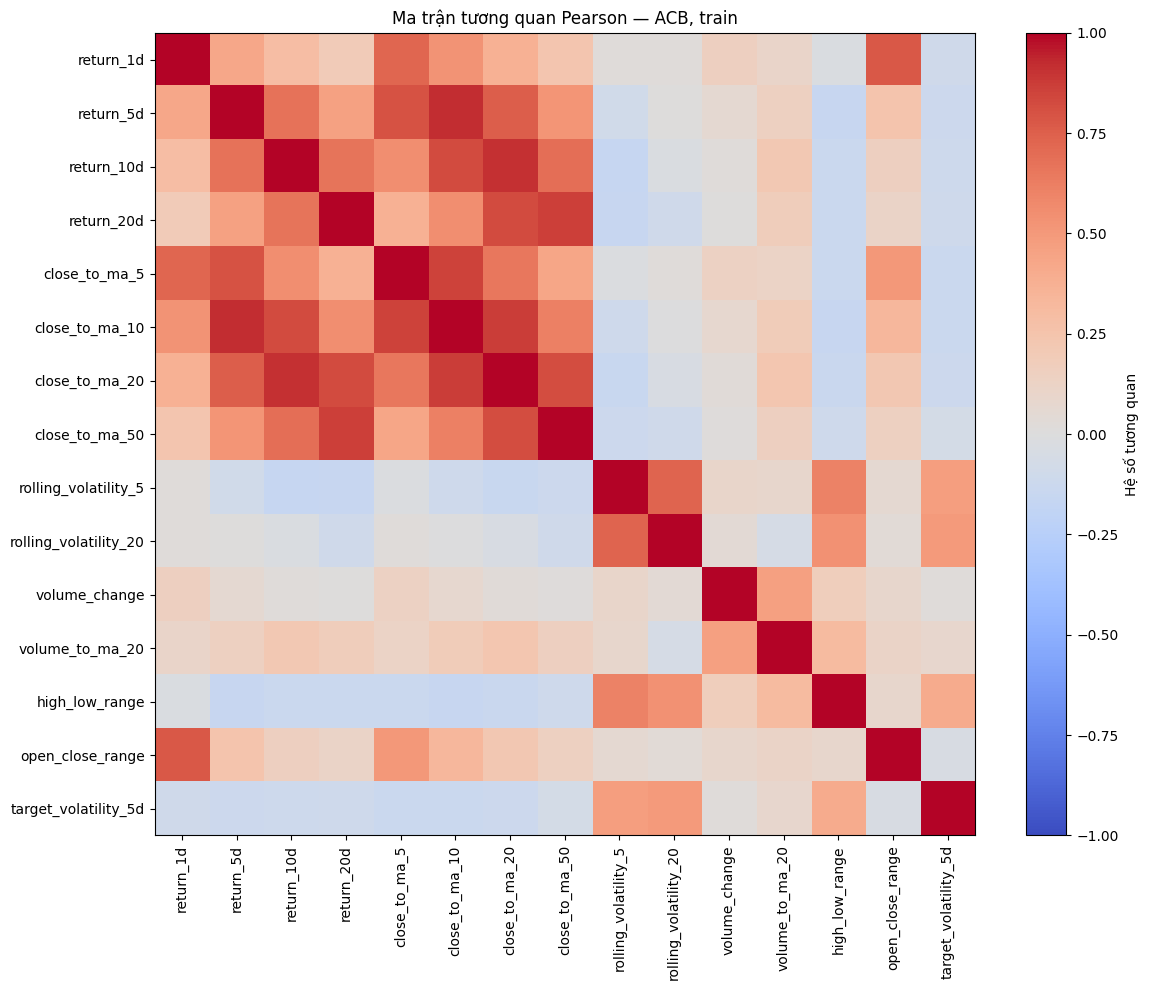

,Tương quan với mục tiêu,Độ lớn tuyệt đối
rolling_volatility_20,0.499191,0.499191
rolling_volatility_5,0.475302,0.475302
high_low_range,0.400258,0.400258
close_to_ma_5,-0.129118,0.129118
close_to_ma_10,-0.126909,0.126909
return_5d,-0.123376,0.123376
close_to_ma_20,-0.119400,0.119400
return_10d,-0.109694,0.109694
return_20d,-0.106069,0.106069
return_1d,-0.097543,0.097543


Các cặp có tương quan tuyệt đối từ 0.85:


,Đặc trưng 1,Đặc trưng 2,Tương quan tuyệt đối
16,return_5d,close_to_ma_10,0.919639
28,return_10d,close_to_ma_20,0.909713
55,close_to_ma_10,close_to_ma_20,0.869291
39,return_20d,close_to_ma_50,0.860134
46,close_to_ma_5,close_to_ma_10,0.857913


In [2]:
corr = train.loc[:, [*features, target]].astype(float).corr(method="pearson")
fig, ax = plt.subplots(figsize=(12, 10))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1, aspect="auto")
ax.set_xticks(range(len(corr.columns)), corr.columns, rotation=90)
ax.set_yticks(range(len(corr.index)), corr.index)
ax.set_title(f"Ma trận tương quan Pearson — {ticker}, train")
fig.colorbar(im, ax=ax, label="Hệ số tương quan")
fig.tight_layout()
plt.show()

target_corr = corr[target].drop(target).rename("Tương quan với mục tiêu").to_frame()
target_corr["Độ lớn tuyệt đối"] = target_corr["Tương quan với mục tiêu"].abs()
display(target_corr.sort_values("Độ lớn tuyệt đối", ascending=False))

abs_corr = corr.loc[list(features), list(features)].abs()
upper = abs_corr.where(np.triu(np.ones(abs_corr.shape), k=1).astype(bool))
pairs = upper.stack().rename("Tương quan tuyệt đối").reset_index()
pairs.columns = ["Đặc trưng 1", "Đặc trưng 2", "Tương quan tuyệt đối"]
pairs = pairs[pairs["Tương quan tuyệt đối"] >= 0.85].sort_values("Tương quan tuyệt đối", ascending=False)
print("Các cặp có tương quan tuyệt đối từ 0.85:")
display(pairs)

## 2. Mutual Information

Mutual Information (MI) ước lượng mức phụ thuộc giữa từng feature và mục tiêu liên tục, có thể phản ánh một số quan hệ phi tuyến mà Pearson không nắm bắt. MI không cho biết chiều tác động và chấm từng feature riêng lẻ nên không đo tương tác giữa các feature. Ước lượng chỉ dùng train, với seed cố định.

,Mutual Information
volume_change,0.009136
volume_to_ma_20,0.023680
open_close_range,0.026723
return_1d,0.070153
return_10d,0.077645
close_to_ma_5,0.088026
close_to_ma_10,0.094283
return_20d,0.095159
high_low_range,0.122048
return_5d,0.126736


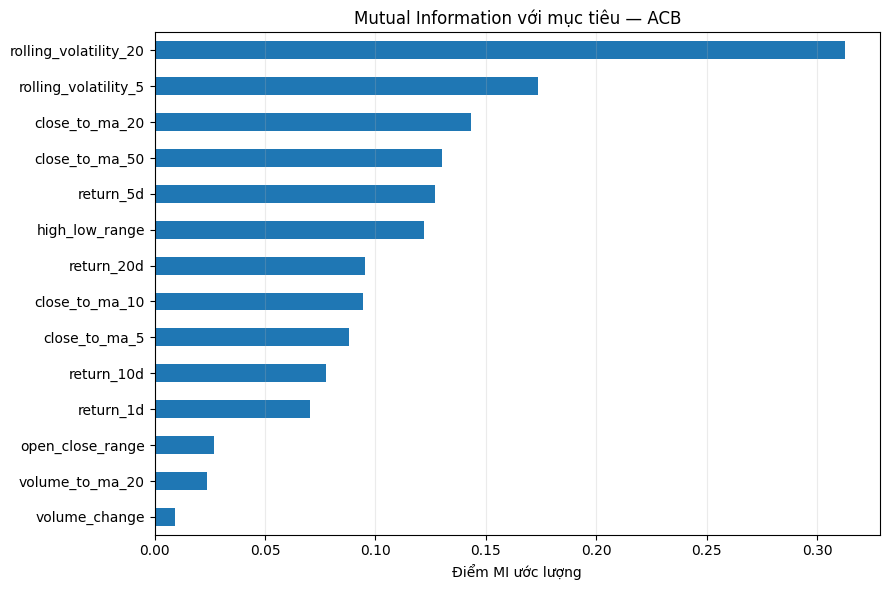

In [3]:
mi = mutual_info_regression(
    X_train, y_train, random_state=int(config["seed"]), n_neighbors=3
)
mi_scores = pd.Series(mi, index=features, name="Mutual Information").sort_values()
display(mi_scores.to_frame())
ax = mi_scores.plot.barh(figsize=(9, 6), title=f"Mutual Information với mục tiêu — {ticker}")
ax.set_xlabel("Điểm MI ước lượng")
ax.grid(axis="x", alpha=.25)
plt.tight_layout()
plt.show()

## 3. Permutation Importance trên validation

Ở mỗi fold, fit XGBoost trên phần train của fold rồi hoán vị từng feature trên cửa sổ validation. Báo cáo RMSE tăng thêm và AP của lớp HIGH giảm đi. Giá trị dương lớn nghĩa là metric suy giảm khi feature bị xáo trộn. Tổng hợp qua các fold giúp xem mức quan trọng có ổn định theo thời gian hay không.

Dùng tham số nền trong config.yaml và 10 lần hoán vị mỗi fold. Đây là tầm quan trọng trong mô hình hiện tại, không chứng minh rằng bỏ feature sẽ cải thiện mô hình rút gọn.

In [4]:
xgb_params = {k: v for k, v in config["models"]["xgboost"].items() if k != "tuning"}
xgb_params["n_jobs"] = 1
high_cutoff = float(np.quantile(
    dataset.validation_folds[0][0][target], warning.q_high
))
n_repeats = 10
rows = []

def high_ap_scorer(estimator, X, y):
    actual_high = np.asarray(y, dtype=float) >= high_cutoff
    if not actual_high.any():
        return 0.0
    if actual_high.all():
        return 1.0
    return float(average_precision_score(actual_high, estimator.predict(X)))

for fold_id, (fold_train, fold_valid) in enumerate(dataset.validation_folds, start=1):
    X_fit = feature_matrix(fold_train, features)
    y_fit = fold_train[target].to_numpy(dtype=float)
    X_val = feature_matrix(fold_valid, features)
    y_val = fold_valid[target].to_numpy(dtype=float)
    model = XGBRegressor(
        objective="reg:squarederror", random_state=int(config["seed"]),
        **xgb_params,
    ).fit(X_fit, y_fit)

    rmse_result = permutation_importance(
        model, X_val, y_val, scoring="neg_root_mean_squared_error",
        n_repeats=n_repeats, random_state=int(config["seed"]) + fold_id, n_jobs=1,
    )
    ap_result = permutation_importance(
        model, X_val, y_val, scoring=high_ap_scorer,
        n_repeats=n_repeats, random_state=int(config["seed"]) + fold_id, n_jobs=1,
    )
    for j, feature in enumerate(features):
        rows.append({
            "fold": fold_id, "feature": feature,
            "rmse_increase": rmse_result.importances_mean[j],
            "rmse_repeat_std": rmse_result.importances_std[j],
            "high_ap_decrease": ap_result.importances_mean[j],
            "high_ap_repeat_std": ap_result.importances_std[j],
        })

fold_scores = pd.DataFrame(rows)
perm = fold_scores.groupby("feature").agg(
    rmse_increase_mean=("rmse_increase", "mean"),
    rmse_fold_std=("rmse_increase", "std"),
    high_ap_decrease_mean=("high_ap_decrease", "mean"),
    high_ap_fold_std=("high_ap_decrease", "std"),
).fillna(0).sort_values("high_ap_decrease_mean", ascending=False)
display(perm)
print(f"Đã đánh giá {len(dataset.validation_folds)} fold, mỗi feature được hoán vị {n_repeats} lần/fold.")

,rmse_increase_mean,rmse_fold_std,high_ap_decrease_mean,high_ap_fold_std
feature,,,,
rolling_volatility_20,0.032222,0.067855,0.045586,0.123754
rolling_volatility_5,0.016125,0.022066,0.013905,0.035547
return_5d,0.013049,0.015726,0.011040,0.033663
close_to_ma_50,0.003817,0.014045,0.010652,0.023276
close_to_ma_5,0.002472,0.006457,0.010516,0.021156
volume_to_ma_20,0.008969,0.018993,0.008393,0.011775
close_to_ma_10,0.003121,0.003623,0.008076,0.015174
open_close_range,0.005280,0.003606,0.005732,0.007567
return_20d,-0.001887,0.017571,0.004853,0.022813


Đã đánh giá 5 fold, mỗi feature được hoán vị 10 lần/fold.


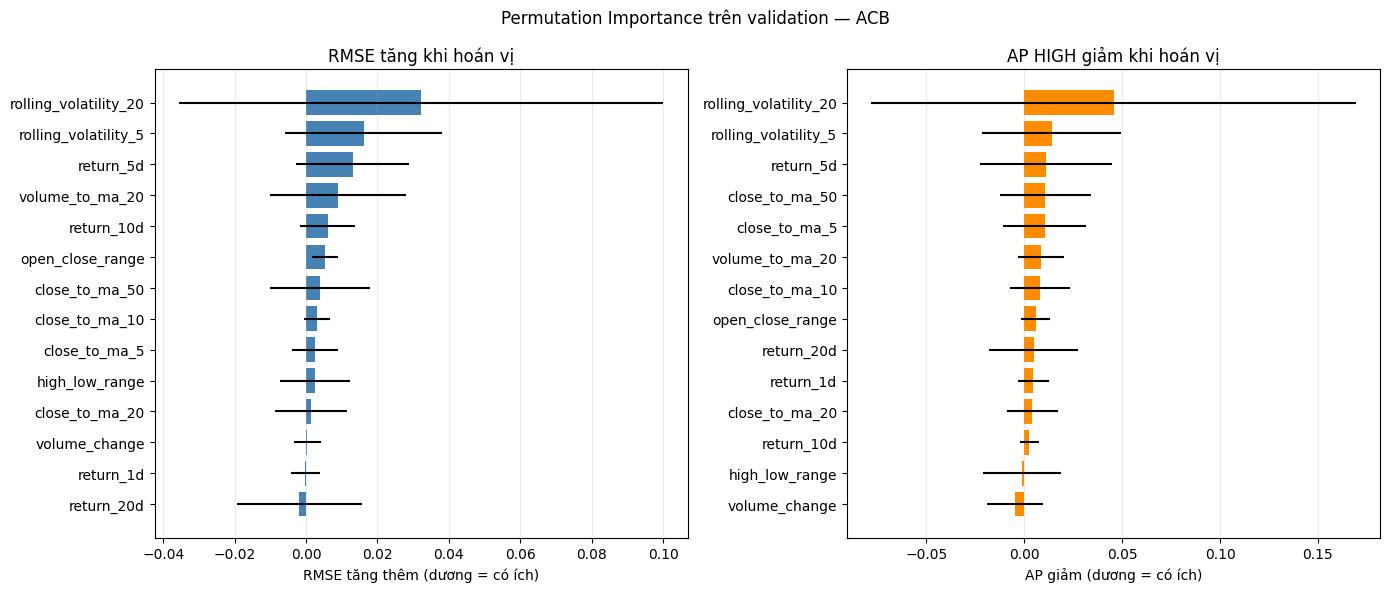

Fold,1,2,3,4,5
Đặc trưng,,,,,
close_to_ma_10,0.009023,0.000557,0.000876,-0.003970,0.033896
close_to_ma_20,0.019158,-0.001537,-0.006810,-0.007601,0.016877
close_to_ma_5,0.004760,-0.000373,0.000639,-0.000609,0.048164
close_to_ma_50,0.032079,0.000342,0.004056,-0.019429,0.036210
high_low_range,-0.030207,0.000607,-0.005256,0.002972,0.025638
open_close_range,0.012269,0.003236,0.002730,-0.004023,0.014445
return_10d,-0.001360,0.006043,-0.003202,0.002981,0.008286
return_1d,0.004466,-0.000982,-0.000761,0.002579,0.017962
return_20d,0.044310,-0.014199,0.001973,-0.003809,-0.004011


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
order_rmse = perm["rmse_increase_mean"].sort_values().index
axes[0].barh(order_rmse, perm.loc[order_rmse, "rmse_increase_mean"],
             xerr=perm.loc[order_rmse, "rmse_fold_std"], color="steelblue")
axes[0].set(title="RMSE tăng khi hoán vị", xlabel="RMSE tăng thêm (dương = có ích)")
axes[0].grid(axis="x", alpha=.25)

order_ap = perm["high_ap_decrease_mean"].sort_values().index
axes[1].barh(order_ap, perm.loc[order_ap, "high_ap_decrease_mean"],
             xerr=perm.loc[order_ap, "high_ap_fold_std"], color="darkorange")
axes[1].set(title="AP HIGH giảm khi hoán vị", xlabel="AP giảm (dương = có ích)")
axes[1].grid(axis="x", alpha=.25)
fig.suptitle(f"Permutation Importance trên validation — {ticker}")
fig.tight_layout()
plt.show()

display(fold_scores.pivot(index="feature", columns="fold", values="high_ap_decrease")
        .rename_axis(index="Đặc trưng", columns="Fold"))

## Tổng hợp và khuyến nghị

- Tương quan cao giữa hai feature gợi ý thông tin trùng lặp; hãy thử bỏ từng biến trong cặp thay vì loại cả nhóm ngay.
- MI thấp là dấu hiệu liên hệ đơn biến yếu theo ước lượng trên train, nhưng không loại trừ tương tác hoặc quan hệ chỉ xuất hiện ở một số giai đoạn.
- Permutation Importance dương và ổn định qua fold là bằng chứng feature có ích cho mô hình và metric đang xét. Điểm gần 0 hoặc âm cần được kiểm chứng; các feature tương quan có thể thay thế nhau và chia sẻ mức quan trọng.
- Không cộng trực tiếp điểm của ba phương pháp vì chúng đo những khía cạnh và thang đo khác nhau.

Để quyết định loại feature, tạo các bộ feature ứng viên dựa trên kết quả này rồi chạy lại tuning và đánh giá trên cùng các fold thời gian. So sánh cả RMSE lẫn AP HIGH, và chỉ chốt nếu cải thiện ổn định qua fold, tốt nhất qua nhiều mã cổ phiếu. Không chọn feature dựa trên test.

In [6]:
summary = pd.DataFrame(index=features)
summary["|Pearson với mục tiêu|"] = target_corr["Độ lớn tuyệt đối"]
summary["Mutual Information"] = mi_scores
summary["RMSE tăng khi hoán vị"] = perm["rmse_increase_mean"]
summary["AP HIGH giảm khi hoán vị"] = perm["high_ap_decrease_mean"]
summary["Độ lệch chuẩn AP qua fold"] = perm["high_ap_fold_std"]
display(summary.sort_values("AP HIGH giảm khi hoán vị", ascending=False))

,|Pearson với mục tiêu|,Mutual Information,RMSE tăng khi hoán vị,AP HIGH giảm khi hoán vị,Độ lệch chuẩn AP qua fold
rolling_volatility_20,0.499191,0.312810,0.032222,0.045586,0.123754
rolling_volatility_5,0.475302,0.173621,0.016125,0.013905,0.035547
return_5d,0.123376,0.126736,0.013049,0.011040,0.033663
close_to_ma_50,0.069931,0.130127,0.003817,0.010652,0.023276
close_to_ma_5,0.129118,0.088026,0.002472,0.010516,0.021156
volume_to_ma_20,0.080114,0.023680,0.008969,0.008393,0.011775
close_to_ma_10,0.126909,0.094283,0.003121,0.008076,0.015174
open_close_range,0.041022,0.026723,0.005280,0.005732,0.007567
return_20d,0.106069,0.095159,-0.001887,0.004853,0.022813
return_1d,0.097543,0.070153,-0.000235,0.004653,0.007787
